In [2]:
import os
import warnings
from pathlib import Path

# Set writable cache locations before importing Spateo/Numba-backed modules.
os.environ.setdefault("XDG_CACHE_HOME", "/private/tmp/cache-spateo")
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/mpl-spateo")
os.environ.setdefault("NUMBA_CACHE_DIR", "/private/tmp/numba-spateo")

import anndata as ad
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spateo as st

# Spateo's digitize() currently emits many pandas chained-assignment
# FutureWarnings while filling adata.obs. They are noisy but not fatal here.
warnings.filterwarnings("ignore", category=FutureWarning, module="spateo.digitization.grid")


/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/spateo/get_version.py:104: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


fastpd is not installed. Please compile the fastpd library.


/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
  warnings.warn(msg, errors.NumbaWarning)
/Users/phillipnicol/miniforge3/envs/spateo-release-morphogam/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:346: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a b

In [3]:
data_dir = Path("../data")
xy = pd.read_csv(data_dir / "ca3_xy.csv")
coords = xy[["xcoord", "ycoord"]].to_numpy(dtype=float)

adata = ad.AnnData(X=np.ones((coords.shape[0], 1)))
adata.obs_names = [f"spot_{i + 1}" for i in range(coords.shape[0])]
adata.var_names = ["dummy"]
adata.obsm["spatial"] = coords
adata.obs["xcoord"] = coords[:, 0]
adata.obs["ycoord"] = coords[:, 1]
adata.uns["__type"] = "UMI"

print(adata)
xy.describe()


AnnData object with n_obs × n_vars = 1456 × 1
    obs: 'xcoord', 'ycoord'
    uns: '__type'
    obsm: 'spatial'


,xcoord,ycoord
count,1456.000000,1456.000000
mean,4915.500275,2917.811882
std,550.523039,405.645632
min,3286.500000,2012.100000
25%,4548.225000,2565.700000
50%,5073.700000,3012.400000
75%,5366.225000,3264.800000
max,5646.900000,3731.600000


In [4]:
# Custom corner rows, using zero-based row numbers from ca3_xy.csv.
custom_corner_rows = {"pnt_XY": 437, "pnt_Xy": 1383, "pnt_xy": 1044, "pnt_xY": 1391}
xy.iloc[list(custom_corner_rows.values())]


,xcoord,ycoord
437,3339.9,3731.6
1383,3402.6,3446.3
1044,4815.9,2190.4
1391,5170.4,2012.1


In [5]:
# The tutorial's digitize() works on image-like ROI coordinates with four user-defined corners.
# Here we use the raw xy tissue coordinates to create a PCA-aligned image coordinate system:
#   axis 0 / columns = longitudinal direction
#   axis 1 / layers  = radial direction
center = coords.mean(axis=0)
coords_centered = coords - center
_, _, vt = np.linalg.svd(coords_centered, full_matrices=False)

longitudinal_axis = vt[0]
radial_axis = vt[1]
longitudinal_score = coords_centered @ longitudinal_axis
radial_score = coords_centered @ radial_axis

# Toggle these after looking at the plots if you want either coordinate direction reversed.
flip_longitudinal = False
flip_radial = False

if flip_longitudinal:
    longitudinal_score = -longitudinal_score
if flip_radial:
    radial_score = -radial_score

def normalize01(x):
    x = np.asarray(x, dtype=float)
    return (x - x.min()) / (x.max() - x.min())

longitudinal01 = normalize01(longitudinal_score)
radial01 = normalize01(radial_score)

# Rescale to a square image-like coordinate system. Keeping both axes within the same
# range avoids axis-shape assumptions inside Spateo's image PDE solver.
#
# Spateo samples the generated field as field[row, col], while OpenCV contours are
# represented as (x=col, y=row). Keep separate arrays so both conventions are correct.
digitize_pad = 50
digitize_scale = 120
longitudinal_img = digitize_pad + digitize_scale * longitudinal01
radial_img = digitize_pad + digitize_scale * radial01

spatial_digitize = np.column_stack([radial_img, longitudinal_img])
contour_digitize = np.column_stack([longitudinal_img, radial_img])

adata.obsm["spatial_digitize"] = spatial_digitize
adata.obs["pca_longitudinal_score"] = longitudinal_score
adata.obs["pca_radial_score"] = radial_score

print("longitudinal_axis:", longitudinal_axis)
print("radial_axis:", radial_axis)
print("spatial_digitize row/col min/max:", spatial_digitize.min(axis=0), spatial_digitize.max(axis=0))
print("contour_digitize x/y min/max:", contour_digitize.min(axis=0), contour_digitize.max(axis=0))


longitudinal_axis: [-0.83462341  0.55082098]
radial_axis: [-0.55082098 -0.83462341]
spatial_digitize row/col min/max: [50. 50.] [170. 170.]
contour_digitize x/y min/max: [50. 50.] [170. 170.]


In [6]:
# Build the region-of-interest contour from the transformed tissue point cloud.
# Use a filled convex hull so every tissue spot is inside the ROI. If the final
# plots look too broad, replace this with a hand-drawn or alpha-shape contour.
img_size = int(np.ceil(max(spatial_digitize.max(), contour_digitize.max()))) + digitize_pad + 1
roi_img = np.zeros((img_size, img_size), dtype=np.uint8)

hull_points = np.round(contour_digitize).astype(np.int32).reshape(-1, 1, 2)
hull = cv2.convexHull(hull_points)
cv2.drawContours(roi_img, [hull], contourIdx=0, color=255, thickness=cv2.FILLED)

roi_img_closed = roi_img

contours, hierarchy = cv2.findContours(
    roi_img_closed,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_NONE,
)

if len(contours) == 0:
    raise RuntimeError("No ROI contour found. Increase point_radius or close_kernel size.")

areas = np.array([cv2.contourArea(c) for c in contours])
ctr_idx = int(np.argmax(areas))

# st.dd.digitize sizes its PDE field from max(adata.obsm[spatial_key]), while
# the drawn contour can extend beyond the observed points by point_radius.
# Keep contour vertices inside the field Spateo will allocate.
field_rowmax = int(np.floor(spatial_digitize[:, 0].max()))
field_colmax = int(np.floor(spatial_digitize[:, 1].max()))
contours = tuple(
    np.stack(
        [
            np.clip(c[:, :, 0], 0, field_colmax),
            np.clip(c[:, :, 1], 0, field_rowmax),
        ],
        axis=2,
    ).astype(np.int32)
    for c in contours
)

print(f"Found {len(contours)} contours; using ctr_idx={ctr_idx}, area={areas[ctr_idx]:.1f}")


Found 1 contours; using ctr_idx=0, area=9205.0


Requested corner rows and snapped Spateo contour points:
  pnt_xy: ca3_xy row=1044, spot=spot_1045, anchor=(74.04, 163.55), contour_point=(76, 167), snap_distance=3.97
  pnt_xY: ca3_xy row=1391, spot=spot_1392, anchor=(56.04, 158.81), contour_point=(56, 159), snap_distance=0.19
  pnt_Xy: ca3_xy row=1383, spot=spot_1384, anchor=(159.56, 136.06), contour_point=(160, 139), snap_distance=2.98
  pnt_XY: ca3_xy row=437, spot=spot_438, anchor=(169.13, 115.31), contour_point=(169, 115), snap_distance=0.34


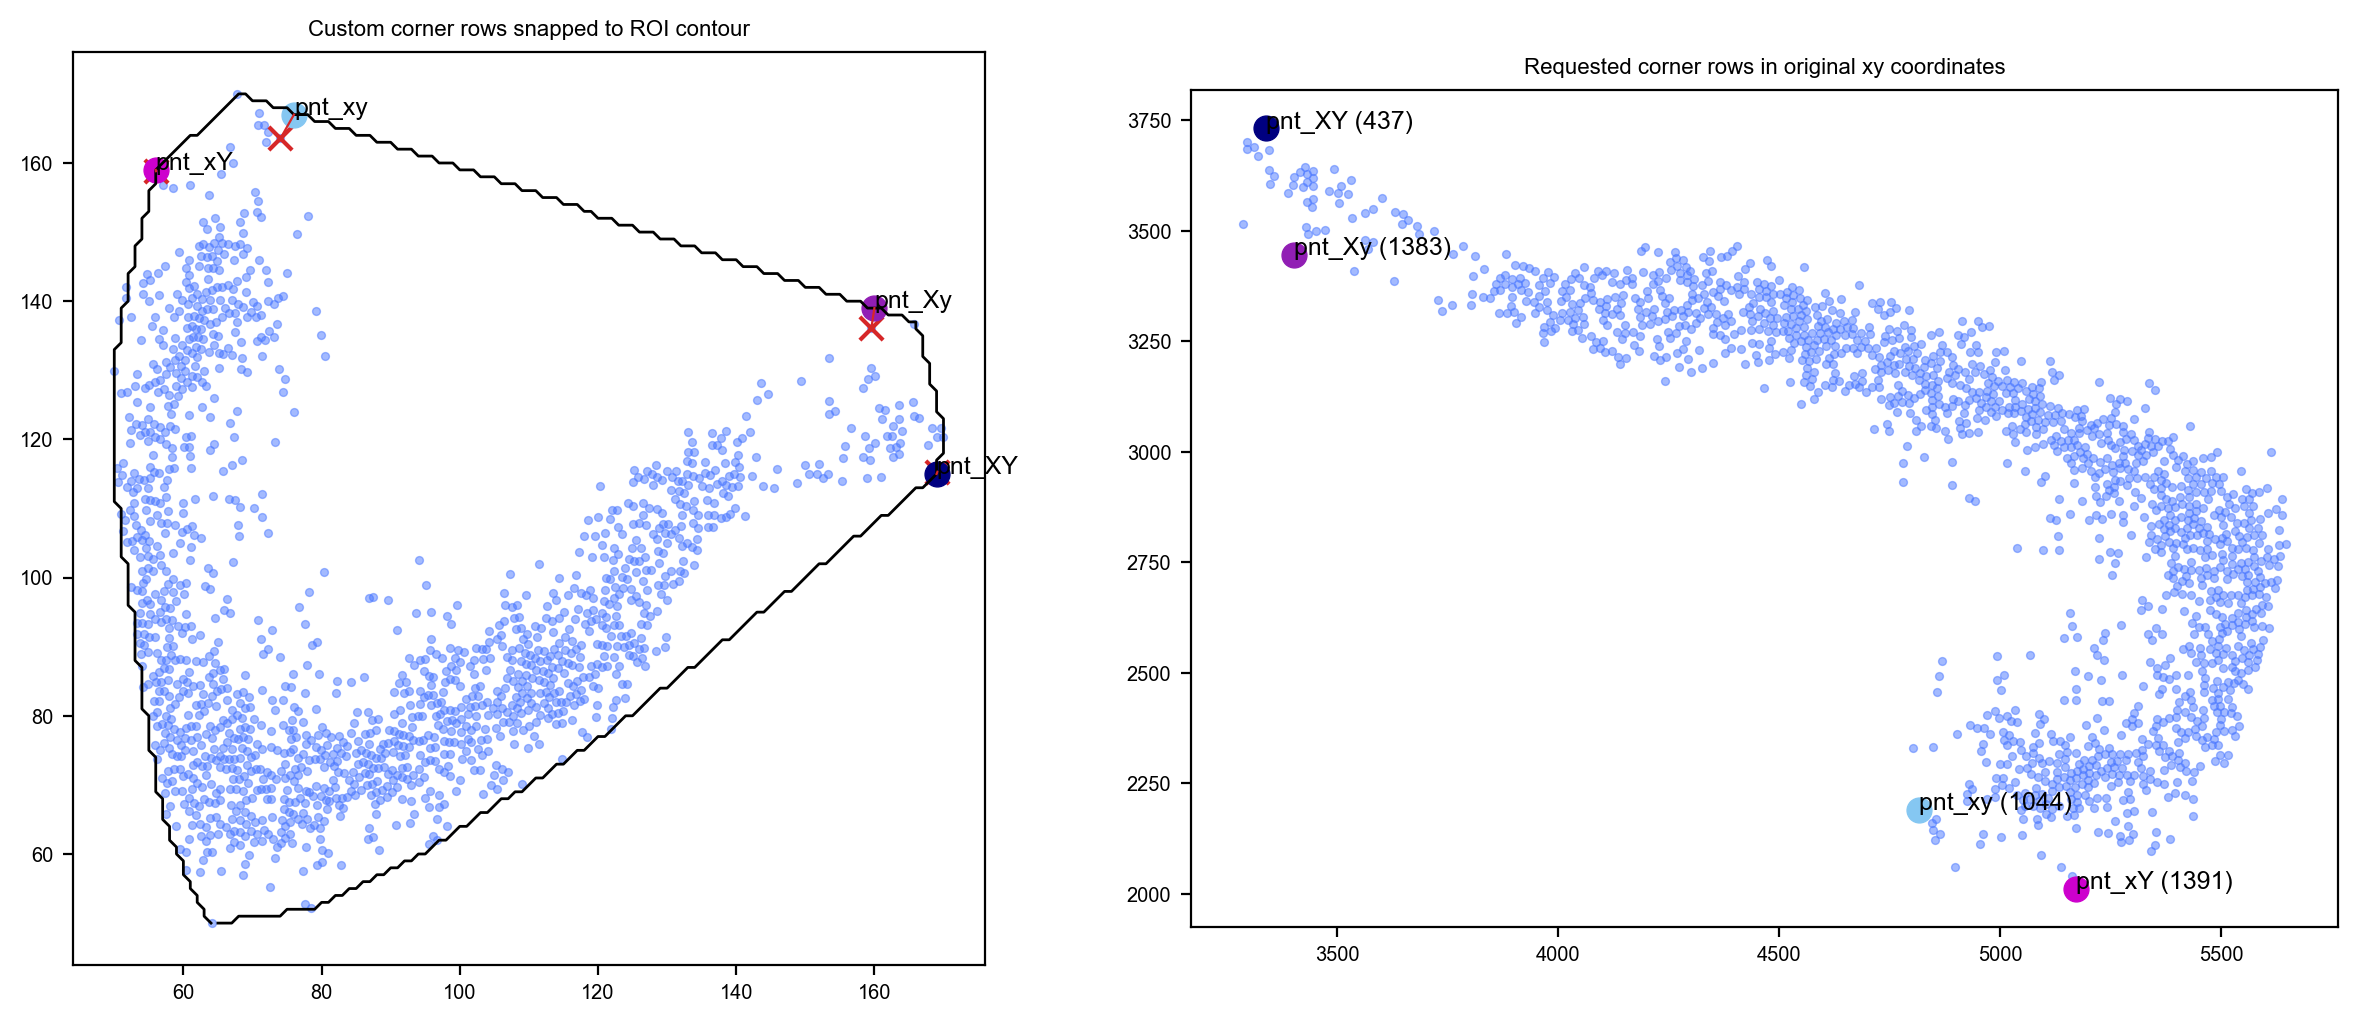

In [7]:
# Match the tutorial's four-corner convention:
#   pnt_xy: min layer, min column
#   pnt_xY: max layer, min column
#   pnt_Xy: min layer, max column
#   pnt_XY: max layer, max column
# In this notebook: column = longitudinal; layer = radial.
#
# These row numbers use zero-based indexing into ca3_xy.csv. Spateo requires each
# pnt_* value to be an exact vertex on contours[ctr_idx], so each requested spot
# is snapped to the nearest ROI contour vertex before calling st.dd.digitize().
corner_row_indices = {
    "pnt_xy": 1044,
    "pnt_xY": 1391,
    "pnt_Xy": 1383,
    "pnt_XY": 437,
}

contour = contours[ctr_idx][:, 0, :]

for name, row_idx in corner_row_indices.items():
    if row_idx < 0 or row_idx >= coords.shape[0]:
        raise IndexError(f"{name} row index {row_idx} is outside ca3_xy.csv with {coords.shape[0]} rows")

def snap_row_to_contour(row_idx):
    anchor = contour_digitize[row_idx]
    d2_contour = (contour[:, 0] - anchor[0]) ** 2 + (contour[:, 1] - anchor[1]) ** 2
    contour_idx = int(np.argmin(d2_contour))
    point = tuple(map(int, contour[contour_idx]))
    return point, row_idx, anchor, float(np.sqrt(d2_contour[contour_idx]))

pnt_xy, idx_xy, anchor_xy, dist_xy = snap_row_to_contour(corner_row_indices["pnt_xy"])
pnt_xY, idx_xY, anchor_xY, dist_xY = snap_row_to_contour(corner_row_indices["pnt_xY"])
pnt_Xy, idx_Xy, anchor_Xy, dist_Xy = snap_row_to_contour(corner_row_indices["pnt_Xy"])
pnt_XY, idx_XY, anchor_XY, dist_XY = snap_row_to_contour(corner_row_indices["pnt_XY"])

corner_points = {
    "pnt_xy": pnt_xy,
    "pnt_xY": pnt_xY,
    "pnt_Xy": pnt_Xy,
    "pnt_XY": pnt_XY,
}
corner_indices = {
    "pnt_xy": idx_xy,
    "pnt_xY": idx_xY,
    "pnt_Xy": idx_Xy,
    "pnt_XY": idx_XY,
}
corner_anchors = {
    "pnt_xy": anchor_xy,
    "pnt_xY": anchor_xY,
    "pnt_Xy": anchor_Xy,
    "pnt_XY": anchor_XY,
}
corner_snap_distances = {
    "pnt_xy": dist_xy,
    "pnt_xY": dist_xY,
    "pnt_Xy": dist_Xy,
    "pnt_XY": dist_XY,
}

print("Requested corner rows and snapped Spateo contour points:")
for name in ["pnt_xy", "pnt_xY", "pnt_Xy", "pnt_XY"]:
    idx = corner_indices[name]
    anchor = corner_anchors[name]
    point = corner_points[name]
    dist = corner_snap_distances[name]
    print(
        f"  {name}: ca3_xy row={idx}, spot={adata.obs_names[idx]}, "
        f"anchor=({anchor[0]:.2f}, {anchor[1]:.2f}), contour_point={point}, snap_distance={dist:.2f}"
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

axes[0].scatter(contour_digitize[:, 0], contour_digitize[:, 1], s=8, alpha=0.5)
axes[0].plot(contour[:, 0], contour[:, 1], color="black", linewidth=1)
for name, idx in corner_indices.items():
    anchor = corner_anchors[name]
    point = corner_points[name]
    axes[0].scatter(anchor[0], anchor[1], s=70, marker="x", color="tab:red")
    axes[0].scatter(point[0], point[1], s=80)
    axes[0].plot([anchor[0], point[0]], [anchor[1], point[1]], color="tab:red", linewidth=0.8)
    axes[0].text(point[0], point[1], name, fontsize=9)
axes[0].set_title("Custom corner rows snapped to ROI contour")
axes[0].set_aspect("equal")

axes[1].scatter(coords[:, 0], coords[:, 1], s=8, alpha=0.5)
for name, idx in corner_indices.items():
    axes[1].scatter(coords[idx, 0], coords[idx, 1], s=80)
    axes[1].text(coords[idx, 0], coords[idx, 1], f"{name} ({idx})", fontsize=9)
axes[1].set_title("Requested corner rows in original xy coordinates")
axes[1].set_aspect("equal")

plt.show()


In [8]:
# This follows the tutorial's "Digitize the region of interest" section.
# Spateo writes radial/layer heat to digital_layer and longitudinal/column heat to digital_column.
st.dd.digitize(
    adata=adata,
    ctrs=contours,
    ctr_idx=ctr_idx,
    pnt_xy=pnt_xy,
    pnt_xY=pnt_xY,
    pnt_Xy=pnt_Xy,
    pnt_XY=pnt_XY,
    spatial_key="spatial_digitize",
    dgl_layer_key="spateo_radial_raw",
    dgl_column_key="spateo_longitudinal_raw",
    max_itr=5000,
    lh=1,
    hh=100,
)

adata.obs["spateo_radial"] = normalize01(adata.obs["spateo_radial_raw"].astype(float).to_numpy())
adata.obs["spateo_longitudinal"] = normalize01(
    adata.obs["spateo_longitudinal_raw"].astype(float).to_numpy()
)

digitized_coords = pd.DataFrame(
    {
        "xcoord": coords[:, 0],
        "ycoord": coords[:, 1],
        "spateo_longitudinal": adata.obs["spateo_longitudinal"].to_numpy(),
        "spateo_radial": adata.obs["spateo_radial"].to_numpy(),
        "spateo_longitudinal_raw": adata.obs["spateo_longitudinal_raw"].to_numpy(),
        "spateo_radial_raw": adata.obs["spateo_radial_raw"].to_numpy(),
        "pca_longitudinal_score": longitudinal_score,
        "pca_radial_score": radial_score,
    },
    index=adata.obs_names,
)

for key in ["spateo_longitudinal_raw", "spateo_radial_raw", "spateo_longitudinal", "spateo_radial"]:
    values = adata.obs[key].astype(float).to_numpy()
    print(f"{key}: zeros={(values == 0).sum()}, min={values.min():.4f}, max={values.max():.4f}")

digitized_coords.head()


|-----> Initialize the field of the spatial domain of interests.
|-----> Prepare the isoline segments with either the highest/lower column or layer heat values.
|-----> Solve the layer heat equation on spatial domain with the iso-layer-line conditions.
|-----> Max iteration reached, with L2 error at: 2.5061105210462178e-05
|-----> Total iteration: 5001
|-----> Saving layer heat values to spateo_radial_raw.
spot_1       0.0
spot_2       0.0
spot_3       0.0
spot_4       0.0
spot_5       0.0
            ... 
spot_1452    0.0
spot_1453    0.0
spot_1454    0.0
spot_1455    0.0
spot_1456    0.0
Name: spateo_radial_raw, Length: 1456, dtype: float64
|-----> Solve the column heat equation on spatial domain with the iso-column-line conditions.
|-----> Max iteration reached, with L2 error at: 2.4014604839747874e-05
|-----> Total iteration: 5001
|-----> Saving column heat values to spateo_longitudinal_raw.
spateo_longitudinal_raw: zeros=4, min=0.0000, max=100.0000
spateo_radial_raw: zeros=4, min=

,xcoord,ycoord,spateo_longitudinal,spateo_radial,spateo_longitudinal_raw,spateo_radial_raw,pca_longitudinal_score,pca_radial_score
spot_1,5387.0,2291.6,0.195710,0.953141,19.570970,95.314079,-738.455356,262.939156
spot_2,5408.2,2921.7,0.483782,0.972790,48.378229,97.279025,-409.077070,-274.634462
spot_3,5310.4,2941.0,0.497003,0.956435,49.700330,95.643459,-316.820055,-236.872402
spot_4,5435.2,2959.8,0.501173,0.982819,50.117277,98.281931,-410.625622,-321.305781
spot_5,4476.8,3235.9,0.652313,0.823309,65.231334,82.330928,541.359131,-23.838474


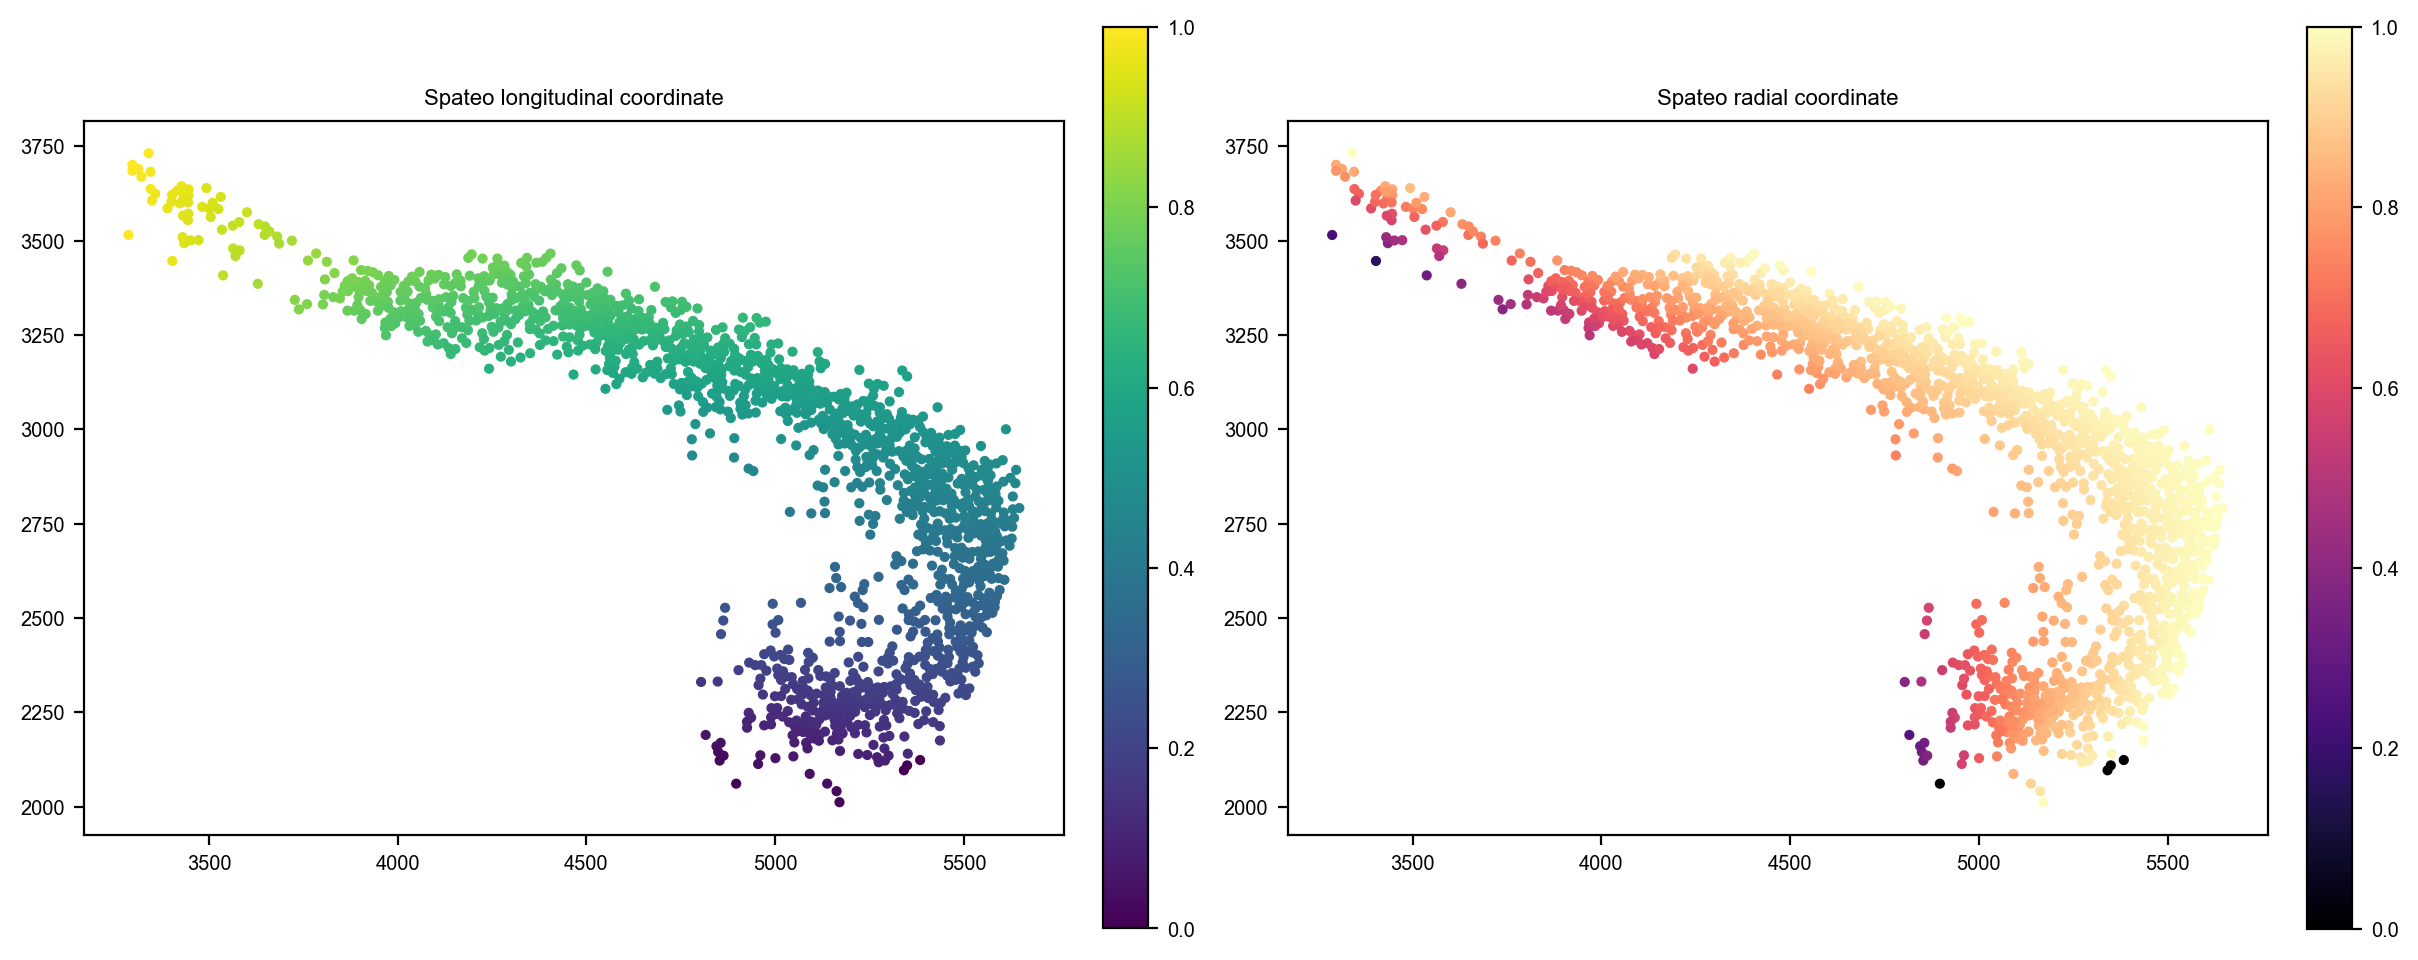

,xcoord,ycoord,spateo_longitudinal,spateo_radial,spateo_longitudinal_raw,spateo_radial_raw,pca_longitudinal_score,pca_radial_score
count,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1456.000000,1.456000e+03,1.456000e+03
mean,4915.500275,2917.811882,0.497842,0.869527,49.784194,86.952701,2.379928e-13,-3.760411e-13
std,550.523039,405.645632,0.217448,0.134145,21.744760,13.414457,6.402882e+02,2.401145e+02
min,3286.500000,2012.100000,0.000000,0.000000,0.000000,0.000000,-8.437479e+02,-4.521627e+02
25%,4548.225000,2565.700000,0.328242,0.816003,32.824230,81.600272,-5.541039e+02,-1.910908e+02
50%,5073.700000,3012.400000,0.523876,0.917304,52.387558,91.730420,-1.963466e+02,-6.317488e+01
75%,5366.225000,3264.800000,0.667990,0.962601,66.799010,96.260075,5.054518e+02,1.756372e+02
max,5646.900000,3731.600000,1.000000,1.000000,100.000000,100.000000,1.782347e+03,7.253039e+02


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

sc0 = axes[0].scatter(
    coords[:, 0],
    coords[:, 1],
    c=adata.obs["spateo_longitudinal"],
    s=10,
    cmap="viridis",
)
axes[0].set_title("Spateo longitudinal coordinate")
axes[0].set_aspect("equal")
plt.colorbar(sc0, ax=axes[0], fraction=0.046, pad=0.04)

sc1 = axes[1].scatter(
    coords[:, 0],
    coords[:, 1],
    c=adata.obs["spateo_radial"],
    s=10,
    cmap="magma",
)
axes[1].set_title("Spateo radial coordinate")
axes[1].set_aspect("equal")
plt.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()

digitized_coords.describe()


In [10]:
#Save longitudinal and radial coordinates for later use

digitized_coords.head()

#Save digitized coords
digitized_coords.to_csv(data_dir / "ca3_xy_digitized.csv", index=True)